In [1]:
import tensorflow as tf

In [2]:
import zipfile
!wget https://storage.googleapis.com/ztm_tf_course/food_vision/pizza_steak.zip

zip_ref = zipfile.ZipFile("pizza_steak.zip")
zip_ref.extractall()
zip_ref.close()

--2026-01-21 05:59:16--  https://storage.googleapis.com/ztm_tf_course/food_vision/pizza_steak.zip
Resolving storage.googleapis.com (storage.googleapis.com)... 142.251.188.207, 192.178.163.207, 74.125.20.207, ...
Connecting to storage.googleapis.com (storage.googleapis.com)|142.251.188.207|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 109540975 (104M) [application/zip]
Saving to: ‘pizza_steak.zip’

pizza_steak.zip     100%[===================>] 104.47M   328MB/s    in 0.3s    

2026-01-21 05:59:16 (328 MB/s) - ‘pizza_steak.zip’ saved [109540975/109540975]



In [3]:
!ls pizza_steak

test  train


In [4]:
!ls pizza_steak/train

pizza  steak


In [5]:
import os

for dirpath, dirnames, filenames in os.walk('pizza_steak'):
  print(f'There are {len(dirnames)} directories and {len(filenames)} images in {dirpath}')

There are 2 directories and 0 images in pizza_steak
There are 2 directories and 0 images in pizza_steak/test
There are 0 directories and 250 images in pizza_steak/test/steak
There are 0 directories and 250 images in pizza_steak/test/pizza
There are 2 directories and 0 images in pizza_steak/train
There are 0 directories and 750 images in pizza_steak/train/steak
There are 0 directories and 750 images in pizza_steak/train/pizza


In [6]:
for i in os.walk('pizza_steak'):
  print(i)

('pizza_steak', ['test', 'train'], [])
('pizza_steak/test', ['steak', 'pizza'], [])
('pizza_steak/test/steak', [], ['867610.jpg', '2315011.jpg', '1627703.jpg', '459522.jpg', '2824517.jpg', '1902895.jpg', '3013404.jpg', '673127.jpg', '526186.jpg', '1868005.jpg', '552171.jpg', '1515274.jpg', '1662212.jpg', '86782.jpg', '144370.jpg', '565095.jpg', '1016217.jpg', '476333.jpg', '2229090.jpg', '864661.jpg', '831681.jpg', '2984679.jpg', '1375503.jpg', '7056.jpg', '3060047.jpg', '285269.jpg', '1951003.jpg', '3622237.jpg', '2756200.jpg', '1163050.jpg', '3315737.jpg', '603417.jpg', '3903517.jpg', '391144.jpg', '928920.jpg', '3553838.jpg', '221604.jpg', '1687010.jpg', '87246.jpg', '2921355.jpg', '904856.jpg', '721500.jpg', '1288540.jpg', '1379840.jpg', '1107549.jpg', '347745.jpg', '653303.jpg', '1206166.jpg', '39461.jpg', '2825105.jpg', '2716791.jpg', '2945937.jpg', '481867.jpg', '2069289.jpg', '400530.jpg', '2353677.jpg', '3137334.jpg', '3842125.jpg', '3088325.jpg', '281731.jpg', '3835895.jpg', 

In [7]:
os.listdir('pizza_steak/train/steak')

['359330.jpg',
 '3253588.jpg',
 '3011642.jpg',
 '240435.jpg',
 '2129685.jpg',
 '168006.jpg',
 '907107.jpg',
 '56240.jpg',
 '2286639.jpg',
 '1995118.jpg',
 '280284.jpg',
 '149682.jpg',
 '2815172.jpg',
 '2090504.jpg',
 '1552530.jpg',
 '1362989.jpg',
 '2490489.jpg',
 '908261.jpg',
 '2938012.jpg',
 '3857508.jpg',
 '590142.jpg',
 '588739.jpg',
 '3047807.jpg',
 '2964732.jpg',
 '401144.jpg',
 '3247009.jpg',
 '1524526.jpg',
 '3663800.jpg',
 '3621565.jpg',
 '2547797.jpg',
 '640539.jpg',
 '3916407.jpg',
 '234626.jpg',
 '2087958.jpg',
 '148916.jpg',
 '203450.jpg',
 '3671021.jpg',
 '1697339.jpg',
 '1941807.jpg',
 '1212161.jpg',
 '3524429.jpg',
 '854150.jpg',
 '134369.jpg',
 '3191589.jpg',
 '2940544.jpg',
 '3577732.jpg',
 '3180182.jpg',
 '3540750.jpg',
 '1371177.jpg',
 '1752330.jpg',
 '1736543.jpg',
 '1539499.jpg',
 '461689.jpg',
 '2544643.jpg',
 '3894222.jpg',
 '313851.jpg',
 '250978.jpg',
 '167069.jpg',
 '3830872.jpg',
 '1334054.jpg',
 '1021458.jpg',
 '2509017.jpg',
 '2154126.jpg',
 '1493169.jpg'

In [8]:
num_steak_images_train = len(os.listdir('pizza_steak/train/steak'))
num_steak_images_train

750

In [9]:
os.listdir('pizza_steak/train')

['steak', 'pizza']

In [10]:
import pathlib
import numpy as np
data_dir = pathlib.Path('pizza_steak/train')


In [11]:
class_names = np.array(sorted([item.name for item in data_dir.glob('*')]))
print(class_names)

['pizza' 'steak']


In [12]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import random
def view_random_image(target_dir, target_class):
  target_folder = target_dir + target_class
  random_image = random.sample(os.listdir(target_folder), 1)
  img = mpimg.imread(target_folder + '/' + random_image[0])
  plt.imshow(img)
  plt.title(target_class)
  plt.axis('off')
  print(f'Image shape: {img.shape}')
  return img

Image shape: (384, 512, 3)


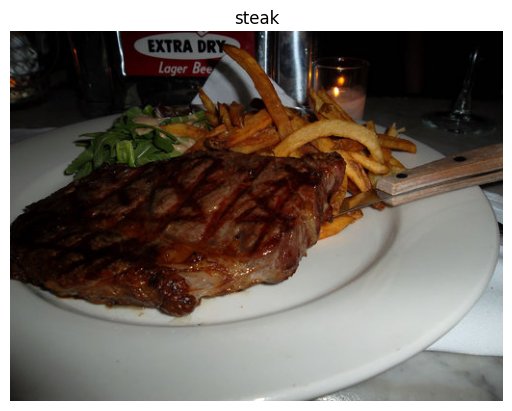

In [13]:
img = view_random_image(target_dir='pizza_steak/train/',
                         target_class='steak')

# flitting model

In [105]:
import tensorflow as ts
from tensorflow.keras.preprocessing.image import ImageDataGenerator

tf.random.set_seed(42)

train_datagen = ImageDataGenerator(rescale=1/255.)
test_datagen = ImageDataGenerator(rescale=1/255.)

train_dir = 'pizza_steak/train/'
valid_dir = 'pizza_steak/test/'

In [15]:
train_data = train_datagen.flow_from_directory(train_dir,
                                               batch_size =32,
                                               target_size = (224,224),
                                               class_mode = 'binary',
                                               seed=42)
valid_data = train_datagen.flow_from_directory(valid_dir,
                                               batch_size =32,
                                               target_size = (224,224),
                                               class_mode = 'binary',
                                               seed=42)
model_1 = tf.keras.Sequential([
  tf.keras.layers.Conv2D(filters=10,
                         kernel_size=3,
                         activation='relu',
                         input_shape=(224,224,3)),
  tf.keras.layers.Conv2D(10,3,activation='relu'),
  tf.keras.layers.MaxPool2D(pool_size=2,
                            padding='valid'),

  tf.keras.layers.Conv2D(10,3,activation='relu'),
  tf.keras.layers.Conv2D(10,3,activation='relu'),
  tf.keras.layers.MaxPool2D(2),
  tf.keras.layers.Flatten(),
  tf.keras.layers.Dense(1,activation='sigmoid')
])

Found 1500 images belonging to 2 classes.
Found 500 images belonging to 2 classes.


/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [16]:
model_1.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 222, 222, 10)   │           280 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 220, 220, 10)   │           910 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 110, 110, 10)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 108, 108, 10)   │           910 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 106, 106, 10)   │           910 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 53, 53, 10)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 28090)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │        28,091 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 31,101 (121.49 KB)

 Trainable params: 31,101 (121.49 KB)

 Non-trainable params: 0 (0.00 B)

In [17]:
optimizer = tf.keras.optimizers.Adam(learning_rate=0.001)
model_1.compile(loss='binary_crossentropy',
                optimizer=optimizer,
                metrics=['accuracy'])

In [18]:
history = model_1.fit(train_data,
                      epochs=5,
                      steps_per_epoch=len(train_data),
                      validation_data=valid_data,
                      validation_steps=len(valid_data))

Epoch 1/5


/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


47/47 ━━━━━━━━━━━━━━━━━━━━ 18s 238ms/step - accuracy: 0.5752 - loss: 0.6533 - val_accuracy: 0.8400 - val_loss: 0.4069
Epoch 2/5
47/47 ━━━━━━━━━━━━━━━━━━━━ 5s 100ms/step - accuracy: 0.7960 - loss: 0.4428 - val_accuracy: 0.8560 - val_loss: 0.3954
Epoch 3/5
47/47 ━━━━━━━━━━━━━━━━━━━━ 6s 131ms/step - accuracy: 0.8344 - loss: 0.4158 - val_accuracy: 0.8680 - val_loss: 0.3543
Epoch 4/5
47/47 ━━━━━━━━━━━━━━━━━━━━ 5s 112ms/step - accuracy: 0.8304 - loss: 0.3874 - val_accuracy: 0.8420 - val_loss: 0.3779
Epoch 5/5
47/47 ━━━━━━━━━━━━━━━━━━━━ 5s 104ms/step - accuracy: 0.8893 - loss: 0.2882 - val_accuracy: 0.8560 - val_loss: 0.3601


In [19]:
model_2=tf.keras.Sequential([
  tf.keras.layers.Flatten(input_shape=(224,224,3)),
  tf.keras.layers.Dense(4,activation='relu'),
  tf.keras.layers.Dense(4,activation='relu'),
  tf.keras.layers.Dense(1,activation='sigmoid')
])
optimizer = tf.keras.optimizers.Adam(learning_rate=1e-3)

model_2.compile(loss='binary_crossentropy',
                optimizer=optimizer,
                metrics=['accuracy'])

/usr/local/lib/python3.12/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [20]:
history_2 = model_2.fit(train_data,
                        epochs=5,
                        steps_per_epoch=len(train_data),
                        validation_data=valid_data,
                        validation_steps=len(valid_data))

Epoch 1/5
47/47 ━━━━━━━━━━━━━━━━━━━━ 9s 140ms/step - accuracy: 0.4548 - loss: 1.2628 - val_accuracy: 0.5000 - val_loss: 0.6932
Epoch 2/5
47/47 ━━━━━━━━━━━━━━━━━━━━ 7s 141ms/step - accuracy: 0.5125 - loss: 0.6931 - val_accuracy: 0.5000 - val_loss: 0.6932
Epoch 3/5
47/47 ━━━━━━━━━━━━━━━━━━━━ 5s 98ms/step - accuracy: 0.5152 - loss: 0.6930 - val_accuracy: 0.5000 - val_loss: 0.6932
Epoch 4/5
47/47 ━━━━━━━━━━━━━━━━━━━━ 7s 140ms/step - accuracy: 0.4787 - loss: 0.6933 - val_accuracy: 0.5000 - val_loss: 0.6931
Epoch 5/5
47/47 ━━━━━━━━━━━━━━━━━━━━ 6s 127ms/step - accuracy: 0.4886 - loss: 0.6932 - val_accuracy: 0.5000 - val_loss: 0.6931


In [21]:
model_3 = tf.keras.Sequential([
  tf.keras.layers.Flatten(input_shape=(224,224,3)),
  tf.keras.layers.Dense(4,activation='relu'),
  tf.keras.layers.Dense(4,activation='relu'),
  tf.keras.layers.Dense(1,activation='sigmoid')
])

optimizer = tf.keras.optimizers.Adam(learning_rate=1e-3)

model_3.compile(loss='binary_crossentropy',
                optimizer=optimizer,
                metrics=['accuracy'])

In [22]:
history = model_3.fit(train_data,
                      epochs=5,
                      steps_per_epoch = len(train_data),
                      validation_data=valid_data,
                      validation_steps=len(valid_data))

Epoch 1/5
47/47 ━━━━━━━━━━━━━━━━━━━━ 10s 189ms/step - accuracy: 0.4977 - loss: 0.9091 - val_accuracy: 0.5000 - val_loss: 0.6932
Epoch 2/5
47/47 ━━━━━━━━━━━━━━━━━━━━ 5s 98ms/step - accuracy: 0.5153 - loss: 0.6931 - val_accuracy: 0.5000 - val_loss: 0.6932
Epoch 3/5
47/47 ━━━━━━━━━━━━━━━━━━━━ 6s 126ms/step - accuracy: 0.4711 - loss: 0.6933 - val_accuracy: 0.5000 - val_loss: 0.6931
Epoch 4/5
47/47 ━━━━━━━━━━━━━━━━━━━━ 9s 105ms/step - accuracy: 0.5003 - loss: 0.6932 - val_accuracy: 0.5000 - val_loss: 0.6931
Epoch 5/5
47/47 ━━━━━━━━━━━━━━━━━━━━ 4s 93ms/step - accuracy: 0.5087 - loss: 0.6931 - val_accuracy: 0.5000 - val_loss: 0.6931


In [23]:
len(train_data)

47

Image shape: (512, 512, 3)
Image shape: (384, 512, 3)


array([[[ 0,  3,  2],
        [ 0,  2,  1],
        [ 0,  2,  1],
        ...,
        [ 3,  5,  2],
        [ 2,  4,  0],
        [ 1,  3,  0]],

       [[ 0,  3,  2],
        [ 0,  2,  1],
        [ 0,  2,  1],
        ...,
        [ 4,  6,  3],
        [ 3,  5,  0],
        [ 2,  4,  0]],

       [[ 0,  2,  1],
        [ 0,  2,  1],
        [ 0,  2,  1],
        ...,
        [ 5,  7,  4],
        [ 4,  6,  1],
        [ 3,  5,  0]],

       ...,

       [[14, 19,  0],
        [15, 20,  0],
        [15, 20,  0],
        ...,
        [16, 20,  6],
        [17, 21,  7],
        [17, 21,  7]],

       [[15, 20,  0],
        [15, 20,  0],
        [16, 21,  1],
        ...,
        [16, 20,  6],
        [17, 21,  7],
        [17, 21,  7]],

       [[16, 21,  1],
        [16, 21,  1],
        [16, 21,  1],
        ...,
        [17, 21,  7],
        [18, 22,  8],
        [18, 22,  8]]], dtype=uint8)
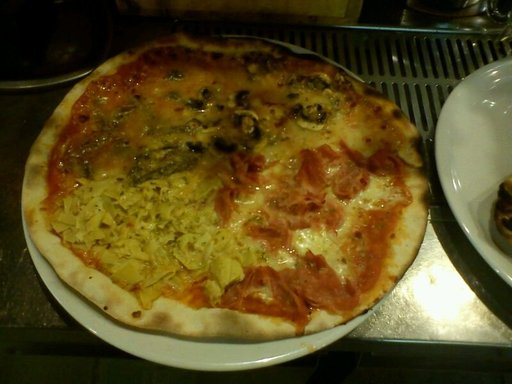

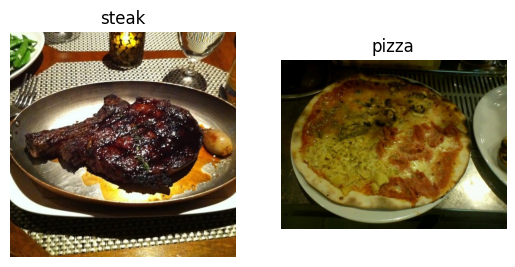

In [24]:
plt.figure()
plt.subplot(1,2,1)
view_random_image('pizza_steak/train/','steak')
plt.subplot(1,2,2)
view_random_image('pizza_steak/train/','pizza')

In [25]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

train_datagen = ImageDataGenerator(1./255)
test_datagen = ImageDataGenerator(1./255)

train_data = train_datagen.flow_from_directory(directory=train_dir,
                                               target_size=(224,224),
                                               class_mode='binary',
                                               batch_size=32)
test_data = test_datagen.flow_from_directory(directory=valid_dir,
                                               target_size=(224,224),
                                               class_mode='binary',
                                               batch_size=32)

Found 1500 images belonging to 2 classes.
Found 500 images belonging to 2 classes.


In [26]:
images,labels = next(train_data)

/usr/local/lib/python3.12/dist-packages/keras/src/legacy/preprocessing/image.py:1263: UserWarning: This ImageDataGenerator specifies `featurewise_center`, but it hasn't been fit on any training data. Fit it first by calling `.fit(numpy_data)`.
  warnings.warn(


In [27]:
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.layers import Dense,Flatten,Conv2D,MaxPool2D
from tensorflow.keras.models import Sequential

In [28]:
tf.keras.backend.clear_session()

In [29]:
model_4 = Sequential([
  Conv2D(filters=10,
         kernel_size=3,
         strides = 2,
         padding='valid',
         activation='relu',
         input_shape=(224,224,3)),
  Conv2D(filters=10,
         kernel_size=3,
         strides=2,
         activation='relu'),
  MaxPool2D(2),
  Conv2D(filters=10,
         kernel_size=3,
         strides=2,
         activation='relu'),
  Conv2D(filters=10,
         kernel_size=3,
         strides=2,
         activation='relu'),
  MaxPool2D(2),
  Flatten(),
  Dense(1,activation='sigmoid')
])

In [30]:
optimizer=Adam(learning_rate=1e-3)
model_4.compile(loss='binary_crossentropy',
                optimizer=optimizer,
                metrics=['accuracy'])

In [31]:
history_4=model_4.fit(train_data,
                      epochs=5,
                      steps_per_epoch=len(train_data),
                      validation_data=valid_data,
                      validation_steps=len(valid_data))


Epoch 1/5
47/47 ━━━━━━━━━━━━━━━━━━━━ 10s 161ms/step - accuracy: 0.5992 - loss: 1.6642 - val_accuracy: 0.5820 - val_loss: 0.6913
Epoch 2/5
47/47 ━━━━━━━━━━━━━━━━━━━━ 4s 92ms/step - accuracy: 0.6865 - loss: 0.6549 - val_accuracy: 0.5180 - val_loss: 0.6907
Epoch 3/5
47/47 ━━━━━━━━━━━━━━━━━━━━ 5s 106ms/step - accuracy: 0.7512 - loss: 0.5336 - val_accuracy: 0.5020 - val_loss: 0.6902
Epoch 4/5
47/47 ━━━━━━━━━━━━━━━━━━━━ 4s 90ms/step - accuracy: 0.7753 - loss: 0.5054 - val_accuracy: 0.5000 - val_loss: 0.6902
Epoch 5/5
47/47 ━━━━━━━━━━━━━━━━━━━━ 4s 90ms/step - accuracy: 0.7813 - loss: 0.4597 - val_accuracy: 0.5000 - val_loss: 0.6909


In [32]:
model_1.evaluate(test_data)

16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 89ms/step - accuracy: 0.7859 - loss: 44.1249


[36.37343215942383, 0.7979999780654907]

In [33]:
model_4.evaluate(test_data)

16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 79ms/step - accuracy: 0.7697 - loss: 0.4787


[0.4637793302536011, 0.7879999876022339]

<Axes: >

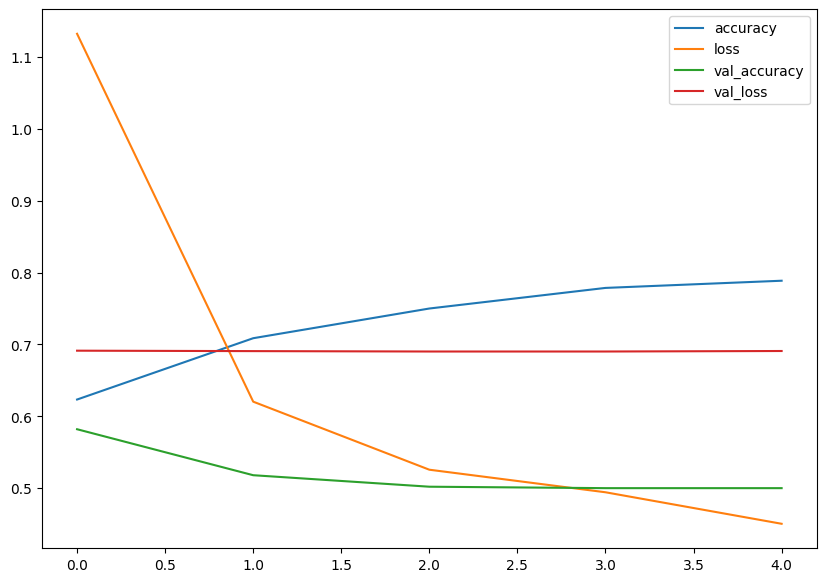

In [34]:
import pandas as pd
pd.DataFrame(history_4.history).plot(figsize=(10,7))

In [35]:
history_4.history

{'accuracy': [0.6233333349227905,
  0.7086666822433472,
  0.75,
  0.7786666750907898,
  0.7886666655540466],
 'loss': [1.132348895072937,
  0.6203510761260986,
  0.5256531238555908,
  0.4942680299282074,
  0.45041438937187195],
 'val_accuracy': [0.5820000171661377,
  0.5180000066757202,
  0.5019999742507935,
  0.5,
  0.5],
 'val_loss': [0.6913122534751892,
  0.690711259841919,
  0.6901589035987854,
  0.6901594400405884,
  0.6908632516860962]}

In [36]:
def plot_loss_curves(history):
  loss = history.history['loss']
  val_loss=history.history['val_loss']
  accuracy=history.history['accuracy']
  val_accuracy=history.history['val_accuracy']
  epochs = range(len(history.history['loss']))
  #plot loss
  plt.plot(epochs,loss,label='training_loss')
  plt.plot(epochs,val_loss,label='val_loss')
  plt.title('loss')
  plt.xlabel('epochs')
  plt.legend()
  #plot accuracy
  plt.figure()
  plt.plot(epochs,accuracy,label='training_accuracy')
  plt.plot(epochs,val_accuracy,label='val_accuracy')
  plt.title('Accuracy')
  plt.xlabel('Epochs')
  plt.legend()

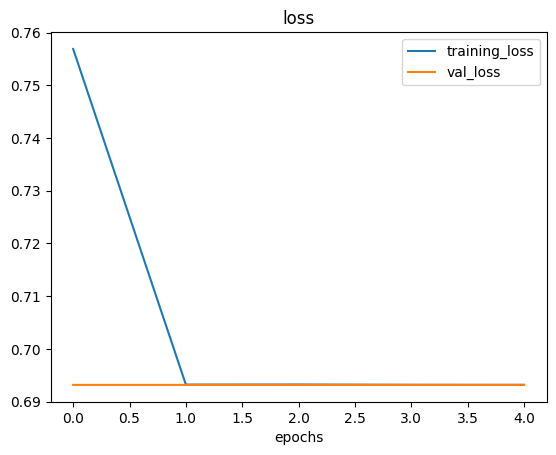

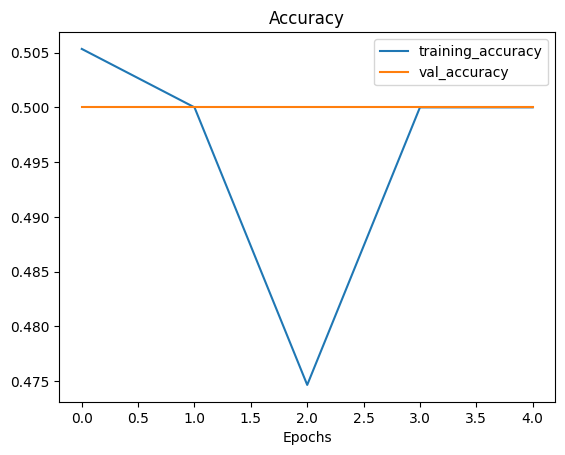

In [37]:
plot_loss_curves(history)

# Data Augmentation

In [38]:
#Augmented Dataset
train_datagen_augmented=ImageDataGenerator(rescale=1./255,
                                           rotation_range=0.2,
                                           shear_range=0.2,
                                           zoom_range = 0.2,
                                           width_shift_range=0.2,
                                           height_shift_range=0.2,
                                           horizontal_flip=True,
                                           vertical_flip=True)
#Normal Dataset
train_datagen=ImageDataGenerator(rescale=1./255)
test_datagen=ImageDataGenerator(rescale=1./255)

In [39]:
print('Train data augmented: ')
train_data_augmented = train_datagen_augmented.flow_from_directory(directory=train_dir,
                                                                 target_size=(224,224),
                                                                 class_mode='binary',
                                                                 batch_size=32,
                                                                 shuffle=False  )
print('Non-Augmented train data: ')
train_data=train_datagen.flow_from_directory(directory=train_dir,
                                               target_size=(224,224),
                                               class_mode='binary',
                                               batch_size=32,
                                                shuffle=False)
IMG_SIZE=(224,224)
print("Non-Augmented test data: ")
test_data=test_datagen.flow_from_directory(directory=valid_dir,
                                               target_size=IMG_SIZE,
                                               class_mode='binary',
                                               batch_size=32)

Train data augmented: 
Found 1500 images belonging to 2 classes.
Non-Augmented train data: 
Found 1500 images belonging to 2 classes.
Non-Augmented test data: 
Found 500 images belonging to 2 classes.


In [40]:
images,labels=next(train_data)
augmented_images,augmented_labels=next(train_data_augmented)

(np.float64(-0.5), np.float64(223.5), np.float64(223.5), np.float64(-0.5))

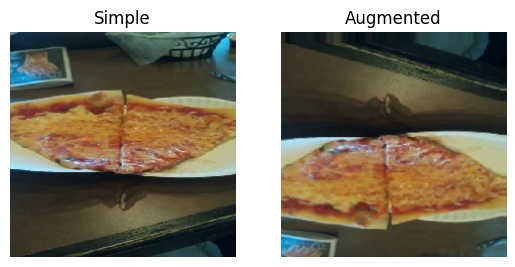

In [41]:
plt.figure()
random_number=np.random.randint(len(augmented_images))

plt.subplot(1,2,1)
plt.imshow(images[random_number])
plt.title('Simple')
plt.axis('off')

plt.subplot(1,2,2)
plt.imshow(augmented_images[random_number])
plt.title('Augmented')
plt.axis('Off')

In [42]:
model_5=tf.keras.Sequential([
    tf.keras.layers.Conv2D(filters=10,
                           kernel_size=(3,3),
                           padding='valid',
                           kernel_initializer='he_normal',
                           activation='relu',
                           input_shape=(224,224,3)),
    tf.keras.layers.Conv2D(filters=10,
                           kernel_size=(3,3),
                           padding='valid',
                           kernel_initializer='he_normal',
                           activation='relu',
                           input_shape=(224,224,3)),
    tf.keras.layers.MaxPool2D(pool_size=(2,2)),
    tf.keras.layers.Conv2D(filters=10,
                           kernel_size=(3,3),
                           padding='valid',
                           kernel_initializer='he_normal',
                           activation='relu',
                           input_shape=(224,224,3)),
    tf.keras.layers.Conv2D(filters=10,
                           kernel_size=(3,3),
                           padding='valid',
                           kernel_initializer='he_normal',
                           activation='relu',
                           input_shape=(224,224,3)),
    tf.keras.layers.MaxPool2D(pool_size=(2,2)),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(1,activation='sigmoid')
])

/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [43]:
optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3)
model_5.compile(loss='binary_crossentropy',
                optimizer=optimizer,
                metrics=['accuracy'])

In [44]:
history_5=model_5.fit(train_data_augmented,
                      epochs=5,
                      steps_per_epoch=len(train_data_augmented),
                      validation_data=test_data,
                      validation_steps=len(test_data))
#

/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/5
47/47 ━━━━━━━━━━━━━━━━━━━━ 24s 464ms/step - accuracy: 0.5422 - loss: 2.0552 - val_accuracy: 0.5000 - val_loss: 0.7253
Epoch 2/5
47/47 ━━━━━━━━━━━━━━━━━━━━ 21s 449ms/step - accuracy: 0.6464 - loss: 0.6598 - val_accuracy: 0.5380 - val_loss: 0.6928
Epoch 3/5
47/47 ━━━━━━━━━━━━━━━━━━━━ 20s 414ms/step - accuracy: 0.5169 - loss: 0.6911 - val_accuracy: 0.6160 - val_loss: 0.6658
Epoch 4/5
47/47 ━━━━━━━━━━━━━━━━━━━━ 20s 426ms/step - accuracy: 0.6180 - loss: 0.6647 - val_accuracy: 0.6600 - val_loss: 0.6591
Epoch 5/5
47/47 ━━━━━━━━━━━━━━━━━━━━ 19s 408ms/step - accuracy: 0.6457 - loss: 0.6719 - val_accuracy: 0.6620 - val_loss: 0.6466


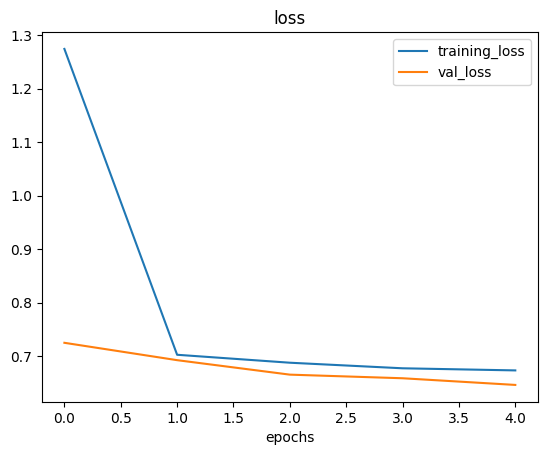

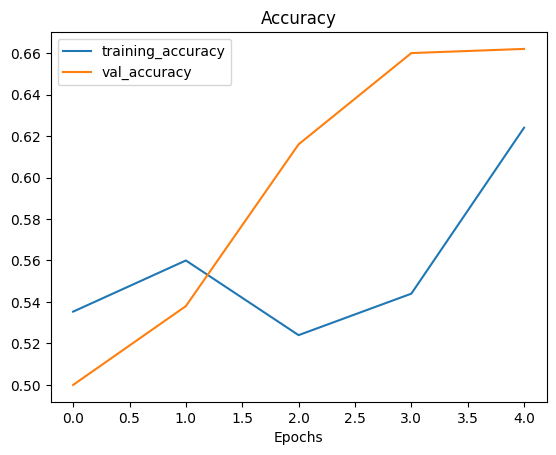

In [45]:
plot_loss_curves(history_5)

In [46]:
#Now let's shuffle data

In [47]:
print('Augmented and shuffled train data ')
train_data_augmented_and_shuffled=train_datagen_augmented.flow_from_directory(directory=train_dir,
                                                                              batch_size=32,
                                                                             target_size=IMG_SIZE,
                                                                             class_mode='binary',
                                                                             shuffle=True)

Augmented and shuffled train data 
Found 1500 images belonging to 2 classes.


In [49]:
model_6=tf.keras.Sequential([
    tf.keras.layers.Conv2D(filters=10,
                           kernel_size=(3,3),
                           padding='valid',
                           kernel_initializer='he_normal',
                           activation='relu',
                           input_shape=(224,224,3)),
    tf.keras.layers.MaxPool2D(pool_size=(2,2)),
    tf.keras.layers.Conv2D(filters=10,
                           kernel_size=(3,3),
                           padding='valid',
                           kernel_initializer='he_normal',
                           activation='relu',),
    tf.keras.layers.MaxPool2D(pool_size=(2,2)),
    tf.keras.layers.Conv2D(filters=10,
                           kernel_size=(3,3),
                           padding='valid',
                           kernel_initializer='he_normal',
                           activation='relu',),
    tf.keras.layers.MaxPool2D(pool_size=(2,2)),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(1,activation='sigmoid')
])

/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [50]:
optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3)
model_6.compile(loss='binary_crossentropy',
                optimizer=optimizer,
                metrics=['accuracy'])

In [51]:
history_6 = model_6.fit(train_data_augmented_and_shuffled,
                        epochs = 5,
                        steps_per_epoch = len(train_data_augmented_and_shuffled),
                        validation_data = test_data,
                        validation_steps = len(test_data))

/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/5
47/47 ━━━━━━━━━━━━━━━━━━━━ 24s 460ms/step - accuracy: 0.5272 - loss: 0.7050 - val_accuracy: 0.6420 - val_loss: 0.5916
Epoch 2/5
47/47 ━━━━━━━━━━━━━━━━━━━━ 19s 413ms/step - accuracy: 0.6985 - loss: 0.5953 - val_accuracy: 0.8140 - val_loss: 0.4394
Epoch 3/5
47/47 ━━━━━━━━━━━━━━━━━━━━ 18s 393ms/step - accuracy: 0.7381 - loss: 0.5364 - val_accuracy: 0.8240 - val_loss: 0.4263
Epoch 4/5
47/47 ━━━━━━━━━━━━━━━━━━━━ 21s 455ms/step - accuracy: 0.7338 - loss: 0.5351 - val_accuracy: 0.8340 - val_loss: 0.4331
Epoch 5/5
47/47 ━━━━━━━━━━━━━━━━━━━━ 19s 411ms/step - accuracy: 0.7357 - loss: 0.5263 - val_accuracy: 0.8340 - val_loss: 0.4409


In [52]:
import matplotlib.image as mpimg
!wget https://raw.githubusercontent.com/mrdbourke/tensorflow-deep-learning/main/images/03-steak.jpeg
steak = mpimg.imread('03-steak.jpeg')

--2026-01-21 06:10:13--  https://raw.githubusercontent.com/mrdbourke/tensorflow-deep-learning/main/images/03-steak.jpeg
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.110.133, 185.199.108.133, 185.199.111.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.110.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 1978213 (1.9M) [image/jpeg]
Saving to: ‘03-steak.jpeg’

03-steak.jpeg       100%[===================>]   1.89M  --.-KB/s    in 0.04s   

2026-01-21 06:10:14 (49.0 MB/s) - ‘03-steak.jpeg’ saved [1978213/1978213]



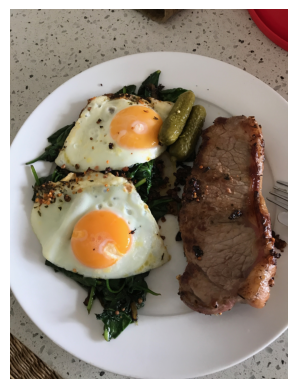

In [54]:
plt.imshow(steak)
plt.axis(False)
plt.show()

In [55]:
steak_norm = ImageDataGenerator(rescale=1/255.)

In [56]:
steak.shape

(4032, 3024, 3)

In [57]:
def load_and_prep_image(filename,img_shape=224):
  img=tf.io.read_file(filename)
  img=tf.image.decode_image(img)
  img = tf.image.resize(img,size = [img_shape,img_shape])
  img = img/255.
  return img

In [58]:
(load_and_prep_image('/content/03-steak.jpeg').shape)

TensorShape([224, 224, 3])

In [59]:
steak = load_and_prep_image('03-steak.jpeg')
pred = model_6.predict(tf.expand_dims(steak,axis=0)).round()

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 735ms/step


In [60]:
pred

array([[1.]], dtype=float32)

In [61]:
class_names

array(['pizza', 'steak'], dtype='<U5')

In [62]:
pred_class=class_names[int(tf.round(pred))]
pred_class

np.str_('steak')

In [63]:
def pred_and_plot(model,filename,class_names = class_names):
  img = load_and_prep_image(filename)
  pred = model.predict(tf.expand_dims(img,axis=0))
  pred_class = class_names[int(tf.round(pred))]

  plt.imshow(img)
  plt.title(f'Prediction:{pred_class}')
  plt.axis(False)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step


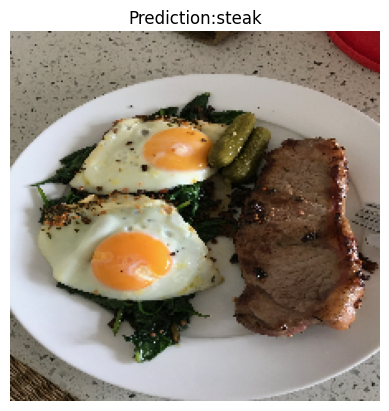

In [65]:
pred_and_plot(model_6,'03-steak.jpeg')

In [67]:
import matplotlib.image as mpimg
!wget https://raw.githubusercontent.com/mrdbourke/tensorflow-deep-learning/main/images/03-pizza-dad.jpeg
pizza = mpimg.imread('03-pizza-dad.jpeg')

--2026-01-21 06:24:56--  https://raw.githubusercontent.com/mrdbourke/tensorflow-deep-learning/main/images/03-pizza-dad.jpeg
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.108.133, 185.199.111.133, 185.199.109.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.108.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 2874848 (2.7M) [image/jpeg]
Saving to: ‘03-pizza-dad.jpeg.1’

03-pizza-dad.jpeg.1 100%[===================>]   2.74M  --.-KB/s    in 0.04s   

2026-01-21 06:24:56 (70.9 MB/s) - ‘03-pizza-dad.jpeg.1’ saved [2874848/2874848]



1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step


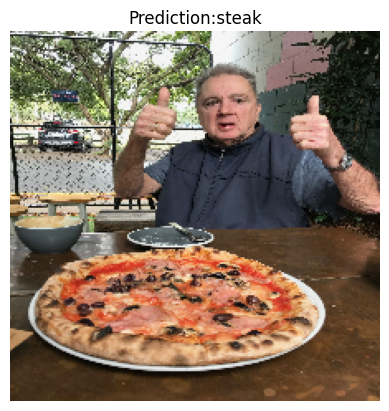

In [69]:
pred_and_plot(model_6,'03-pizza-dad.jpeg')

# 10 food classes

In [113]:
!wget https://storage.googleapis.com/ztm_tf_course/food_vision/10_food_classes_all_data.zip

import zipfile
zip_ref = zipfile.ZipFile('10_food_classes_all_data.zip', 'r')
zip_ref.extractall()
zip_ref.close()

import os

for dirpath, dirnames, filenames in os.walk('10_food_classes_all_data'):
  print(f'There are {len(dirnames)} directories and {len(filenames)} images in {dirpath}.')

--2026-01-21 07:24:14--  https://storage.googleapis.com/ztm_tf_course/food_vision/10_food_classes_all_data.zip
Resolving storage.googleapis.com (storage.googleapis.com)... 108.177.98.207, 74.125.135.207, 74.125.142.207, ...
Connecting to storage.googleapis.com (storage.googleapis.com)|108.177.98.207|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 519183241 (495M) [application/zip]
Saving to: ‘10_food_classes_all_data.zip.1’

10_food_classes_all 100%[===================>] 495.13M  84.7MB/s    in 7.1s    

2026-01-21 07:24:21 (70.2 MB/s) - ‘10_food_classes_all_data.zip.1’ saved [519183241/519183241]

There are 2 directories and 0 images in 10_food_classes_all_data.
There are 10 directories and 0 images in 10_food_classes_all_data/test.
There are 0 directories and 250 images in 10_food_classes_all_data/test/hamburger.
There are 0 directories and 250 images in 10_food_classes_all_data/test/steak.
There are 0 directories and 250 images in 10_food_classes_all_data/t

In [114]:
train_dir='/content/10_food_classes_all_data/train/'
test_dir='/content/10_food_classes_all_data/test/'

In [115]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator
train_datagen_augmentation=ImageDataGenerator(rescale=1/255.,
                                              rotation_range=0.2,
                                              width_shift_range=0.2,
                                              height_shift_range=0.2,
                                              shear_range=0.2,
                                              zoom_range=0.2,
                                              horizontal_flip=True,
                                              vertical_flip=True)
test_datagen=ImageDataGenerator(rescale=1/255.)


In [78]:
IMG_SIZE=(224,224)
batch_size=32

In [116]:
augmented_train = train_datagen_augmentation.flow_from_directory(directory = train_dir,
                                                                 target_size=IMG_SIZE,
                                                                 class_mode='categorical',
                                                                 batch_size=batch_size)
test_data = test_datagen.flow_from_directory(directory = test_dir,
                                                                 target_size=IMG_SIZE,
                                                                 class_mode='categorical',
                                                                 batch_size=batch_size)

Found 7500 images belonging to 10 classes.
Found 2500 images belonging to 10 classes.


In [117]:
images,labels=next(augmented_train)

In [118]:
images.shape

(32, 224, 224, 3)

In [119]:
labels.shape

(32, 10)

(np.float64(-0.5), np.float64(223.5), np.float64(223.5), np.float64(-0.5))

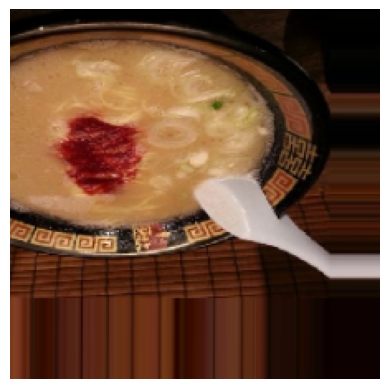

In [120]:
import matplotlib.pyplot as plt
import numpy as np

plt.imshow(images[np.random.randint(len(images))])
plt.axis(False)

In [121]:
import tensorflow as tf

model_7 = tf.keras.Sequential([
    tf.keras.layers.Conv2D(filters=10,
                           kernel_size=(3,3),
                           padding='valid',
                           kernel_initializer='he_normal',
                           activation='relu',
                           input_shape=(224,224,3)),
    tf.keras.layers.Conv2D(filters=10,
                           kernel_size=(3,3),
                           padding='valid',
                           kernel_initializer='he_normal',
                           activation='relu'),
    tf.keras.layers.MaxPool2D(pool_size=(2,2)),
    tf.keras.layers.Conv2D(filters=10,
                           kernel_size=(3,3),
                           padding='valid',
                           kernel_initializer='he_normal',
                           activation='relu'),
    tf.keras.layers.Conv2D(filters=10,
                           kernel_size=(3,3),
                           padding='valid',
                           kernel_initializer='he_normal',
                           activation='relu'),
    tf.keras.layers.MaxPool2D(pool_size=(2,2)),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(10,activation='softmax')
])

/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [122]:
optimizer = tf.keras.optimizers.Adam(learning_rate=1e-3)
model_7.compile(loss='categorical_crossentropy',
                optimizer=optimizer,
                metrics=['accuracy'])

In [123]:
images.shape

(32, 224, 224, 3)

In [124]:
tf.expand_dims(labels,axis=0)

<tf.Tensor: shape=(1, 32, 10), dtype=float32, numpy=
array([[[0., 0., 0., 1., 0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 1., 0., 0., 0., 0.],
        [0., 0., 1., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 1., 0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 1., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 0., 1., 0., 0.],
        [0., 0., 1., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 1., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 0., 1., 0., 0.],
        [0., 0., 0., 1., 0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 1., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 0., 1., 0., 0.],
        [0., 1., 0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 1., 0., 0., 0., 0.],
        [0., 0., 1., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 1., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 1., 0., 0., 0., 0., 0., 0.],
        [1., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 1., 0., 0., 0., 0.

In [125]:
checkpoint_cb=tf.keras.callbacks.ModelCheckpoint('MyCheckpoint.weights.h5',
                                                  save_best_only=True)
early_stopping_cb=tf.keras.callbacks.EarlyStopping(patience=10,
                                                   restore_best_weights=True)

In [126]:
history_7 = model_7.fit(augmented_train,
                        epochs=5,
                        steps_per_epoch=len(augmented_train),
                        validation_data=test_data,
                        validation_steps=len(test_data),
                        callbacks=[checkpoint_cb,early_stopping_cb])

Epoch 1/5
 28/235 ━━━━━━━━━━━━━━━━━━━━ 1:19 384ms/step - accuracy: 0.0798 - loss: 6.8469

KeyboardInterrupt: 

In [ ]:
plot_loss_curves(history_7)

In [ ]:
!wget https://thekittchen.com/wp-content/uploads/2016/04/PRE-Brand-Steak-and-Blue-Cheese-Pizza-2.jpg

In [ ]:
pred_and_plot(model_7,'PRE-Brand-Steak-and-Blue-Cheese-Pizza-2.jpg')

# another version of 10 food classes

In [127]:
import pathlib
import numpy as np
data_dir=pathlib.Path(train_dir)
class_names = np.array(sorted([item.name for item in data_dir.glob('*')]))
class_names

array(['chicken_curry', 'chicken_wings', 'fried_rice', 'grilled_salmon',
       'hamburger', 'ice_cream', 'pizza', 'ramen', 'steak', 'sushi'],
      dtype='<U14')

Image shape: (512, 511, 3)


array([[[ 86,  81,  23],
        [ 86,  81,  23],
        [ 85,  80,  22],
        ...,
        [ 25,  27,  16],
        [ 23,  25,  14],
        [ 21,  22,  14]],

       [[ 85,  80,  22],
        [ 85,  80,  22],
        [ 85,  80,  22],
        ...,
        [ 25,  27,  16],
        [ 25,  27,  16],
        [ 24,  25,  17]],

       [[ 85,  80,  22],
        [ 85,  80,  22],
        [ 85,  80,  22],
        ...,
        [ 24,  26,  15],
        [ 25,  27,  16],
        [ 25,  27,  16]],

       ...,

       [[177, 195, 195],
        [178, 196, 196],
        [178, 196, 196],
        ...,
        [171, 180, 187],
        [172, 181, 188],
        [173, 182, 189]],

       [[176, 194, 194],
        [177, 195, 195],
        [177, 195, 195],
        ...,
        [169, 178, 185],
        [170, 179, 186],
        [171, 180, 187]],

       [[175, 193, 193],
        [175, 193, 193],
        [177, 195, 195],
        ...,
        [171, 180, 187],
        [172, 181, 188],
        [172, 181, 188]]], dtype=uint8)
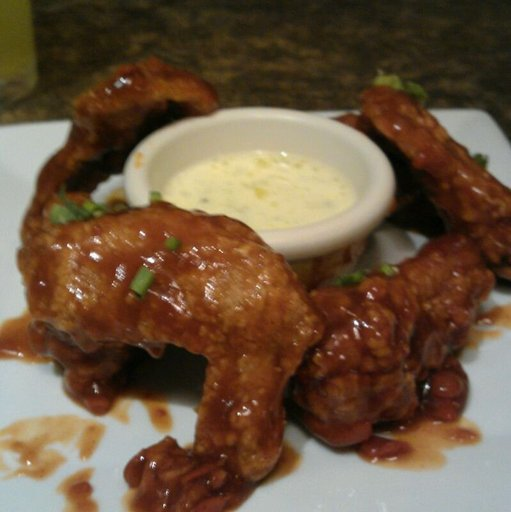

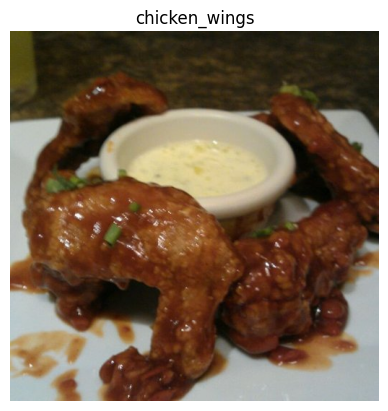

In [128]:
import random
view_random_image(target_dir = train_dir, target_class = random.choice(class_names))


In [129]:
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
tf.random.set_seed(42)

train_datagen = ImageDataGenerator(rescale = 1/255.)
test_datagen = ImageDataGenerator(rescale = 1/255.)

train_data = test_datagen.flow_from_directory(train_dir,
                                              target_size = (224, 224),
                                              batch_size=32)
test_data = test_datagen.flow_from_directory(test_dir,
                                             target_size = (224, 224),
                                             batch_size=32)

Found 7500 images belonging to 10 classes.
Found 2500 images belonging to 10 classes.


In [130]:
model_1_categorical = tf.keras.Sequential([
    tf.keras.layers.Conv2D(filters=10,
                           kernel_size=(3, 3),
                           padding='valid',
                           kernel_initializer='he_normal',
                           activation='relu',
                           input_shape=(224, 224, 3)),
    tf.keras.layers.Conv2D(filters=10,
                           kernel_size=(3, 3),
                           padding='valid',
                           kernel_initializer='he_normal',
                           activation='relu'),
    tf.keras.layers.MaxPool2D(pool_size=(2, 2)),
    tf.keras.layers.Conv2D(filters=10,
                           kernel_size=(3, 3),
                           padding='valid',
                           kernel_initializer='he_normal',
                           activation='relu'),
    tf.keras.layers.Conv2D(filters=10,
                           kernel_size=(3, 3),
                           padding='valid',
                           kernel_initializer='he_normal',
                           activation='relu'),
    tf.keras.layers.MaxPool2D(pool_size=(2, 2)),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(10, activation='softmax')

])

In [132]:
optimizer =  tf.keras.optimizers.Adam(learning_rate=1e-3)
model_1_categorical.compile(loss='categorical_crossentropy',
                            optimizer=optimizer,
                            metrics=['accuracy'])

In [133]:
model_1_categorical.fit(train_data,
                        epochs=5,
                        steps_per_epoch=len(train_data),
                        validation_data=test_data,
                        validation_steps=len(test_data))

/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/5
235/235 ━━━━━━━━━━━━━━━━━━━━ 33s 130ms/step - accuracy: 0.1354 - loss: 2.4849 - val_accuracy: 0.2764 - val_loss: 2.0225
Epoch 2/5
235/235 ━━━━━━━━━━━━━━━━━━━━ 32s 135ms/step - accuracy: 0.4254 - loss: 1.7380 - val_accuracy: 0.3136 - val_loss: 1.9790
Epoch 3/5
235/235 ━━━━━━━━━━━━━━━━━━━━ 37s 158ms/step - accuracy: 0.6842 - loss: 1.0183 - val_accuracy: 0.2632 - val_loss: 2.3795
Epoch 4/5
235/235 ━━━━━━━━━━━━━━━━━━━━ 39s 151ms/step - accuracy: 0.8872 - loss: 0.4011 - val_accuracy: 0.2716 - val_loss: 3.1008
Epoch 5/5
235/235 ━━━━━━━━━━━━━━━━━━━━ 33s 139ms/step - accuracy: 0.9706 - loss: 0.1366 - val_accuracy: 0.2628 - val_loss: 4.3432


In [135]:
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
cp = ModelCheckpoint('MyCheckpoint.weights.h5', save_weights_only=True)
es = EarlyStopping(restore_best_weights=True,
                   patience=1,
                   monitor='loss',
                   #mode = 'min'
                   )

In [136]:
model_1_categorical_history = model_1_categorical.fit(train_data,
                                                      epochs=5,
                                                      steps_per_epoch=len(train_data),
                                                      validation_steps=len(test_data),
                                                      callbacks=[es, cp])

Epoch 1/5
235/235 ━━━━━━━━━━━━━━━━━━━━ 19s 79ms/step - accuracy: 0.9939 - loss: 0.0394
Epoch 2/5
235/235 ━━━━━━━━━━━━━━━━━━━━ 18s 76ms/step - accuracy: 0.9942 - loss: 0.0313
Epoch 3/5
235/235 ━━━━━━━━━━━━━━━━━━━━ 18s 78ms/step - accuracy: 0.9964 - loss: 0.0258
Epoch 4/5
235/235 ━━━━━━━━━━━━━━━━━━━━ 18s 77ms/step - accuracy: 0.9863 - loss: 0.0577


In [137]:
model_1_categorical_history.history

{'accuracy': [0.9906666874885559,
  0.9898666739463806,
  0.9923999905586243,
  0.9883999824523926],
 'loss': [0.046087879687547684,
  0.045910805463790894,
  0.03704576939344406,
  0.04777327552437782]}

In [141]:
model_2_categorical = tf.keras.Sequential([
    tf.keras.layers.Conv2D(filters=10,
                           kernel_size=(3,3),
                           padding='valid',
                           kernel_initializer='he_normal',
                           activation='relu',
                           strides=(2,2),
                           input_shape=(224,224,3)),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Conv2D(filters=10,
                           kernel_size=(3,3),
                           padding='valid',
                           kernel_initializer='he_normal',
                           activation='relu',
                           strides=(2,2)),
    tf.keras.layers.MaxPool2D(pool_size=(2,2)),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Conv2D(filters=10,
                           kernel_size=(3,3),
                           padding='valid',
                           kernel_initializer='he_normal',
                           activation='relu',
                           strides=(2,2)),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Conv2D(filters=10,
                           kernel_size=(3, 3),
                           padding='valid',
                           kernel_initializer='he_normal',
                           activation='relu',
                           strides=(2, 2)),
    tf.keras.layers.MaxPool2D(pool_size=(2, 2)),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dropout(0.5),
    tf.keras.layers.Dense(10, activation='softmax')

])

In [143]:
optimizer =  tf.keras.optimizers.Adam(learning_rate=1e-3)
model_2_categorical.compile(loss='categorical_crossentropy',
                            optimizer=optimizer,
                            metrics=['accuracy'])

In [144]:
model_2_categorical_history = model_2_categorical.fit(train_data,
                                                      epochs=5,
                                                      steps_per_epoch=len(train_data),
                                                      validation_data=test_data,
                                                      validation_steps=len(test_data))

Epoch 1/5
235/235 ━━━━━━━━━━━━━━━━━━━━ 32s 112ms/step - accuracy: 0.1042 - loss: 3.4567 - val_accuracy: 0.1560 - val_loss: 2.2720
Epoch 2/5
235/235 ━━━━━━━━━━━━━━━━━━━━ 22s 94ms/step - accuracy: 0.1289 - loss: 2.3137 - val_accuracy: 0.1716 - val_loss: 2.2392
Epoch 3/5
235/235 ━━━━━━━━━━━━━━━━━━━━ 22s 94ms/step - accuracy: 0.1446 - loss: 2.2660 - val_accuracy: 0.1980 - val_loss: 2.2116
Epoch 4/5
235/235 ━━━━━━━━━━━━━━━━━━━━ 22s 93ms/step - accuracy: 0.1720 - loss: 2.2319 - val_accuracy: 0.2196 - val_loss: 2.1557
Epoch 5/5
235/235 ━━━━━━━━━━━━━━━━━━━━ 22s 93ms/step - accuracy: 0.1952 - loss: 2.1915 - val_accuracy: 0.2492 - val_loss: 2.1026


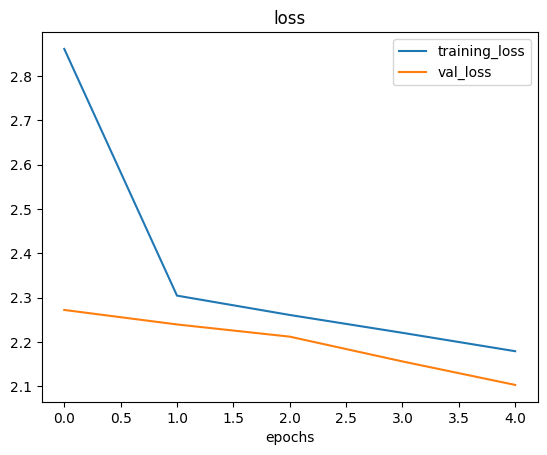

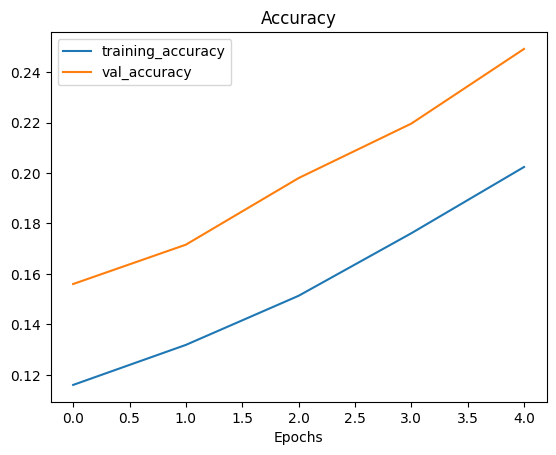

In [145]:
plot_loss_curves(model_2_categorical_history)

In [146]:
model_2_categorical.evaluate(test_data)

79/79 ━━━━━━━━━━━━━━━━━━━━ 9s 116ms/step - accuracy: 0.2523 - loss: 2.1035


[2.1026101112365723, 0.2492000013589859]

In [147]:
model_2_copy=tf.keras.models.clone_model(model_2_categorical)

In [148]:
model_2_copy.summary()

Model: "sequential_7"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_33 (Conv2D)              │ (None, 111, 111, 10)   │           280 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 111, 111, 10)   │            40 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_34 (Conv2D)              │ (None, 55, 55, 10)     │           910 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_16 (MaxPooling2D) │ (None, 27, 27, 10)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 27, 27, 10)     │            40 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_35 (Conv2D)              │ (None, 13, 13, 10)     │           910 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 13, 13, 10)     │            40 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_36 (Conv2D)              │ (None, 6, 6, 10)       │           910 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_17 (MaxPooling2D) │ (None, 3, 3, 10)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_7 (Flatten)             │ (None, 90)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 90)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 10)             │           910 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 12,002 (46.89 KB)

 Trainable params: 3,980 (15.55 KB)

 Non-trainable params: 60 (240.00 B)

 Optimizer params: 7,962 (31.11 KB)